## Abruf der Teilprogramme und Ergebnis Darstellung

In [3]:
#IMPORTS allgemein
import os
import pandas as pd
import matplotlib.pyplot as plt

#HILFSFUNKTIONEN
from merge_teilprojekte_test.functions.hilfsfunktionen import *

#PV IMPORTS
from merge_teilprojekte_test.functions.functions_weather_data import DWDWeatherConfig, DWDWeatherFetcher
from merge_teilprojekte_test.functions.pv_baukasten import PV_System, PV_TYPEN

#INDUSTRIE IMPORT
from merge_teilprojekte_test.functions.Industriegebiet import IndustryLoadAggregator

#ENERGIELANDSCHAFT IMPORT
from merge_teilprojekte_test.functions.Energielandschaft import main

#BATTERIE IMPORT
from merge_teilprojekte_test.functions.battery_storage_eff import BatteryStorageEff

In [4]:
# ------------------------------------------------------------
# 1) Wetterdaten laden (CSV ODER DWD)
# ------------------------------------------------------------
#WETTERDATEN CSV
USE_EXISTING_WEATHER = True
weather_csv = "./functions/inputs/wetter_daten_15min.csv"

print("→ Verwende vorhandene Wetterdaten-CSV")
weather_df = pd.read_csv(weather_csv, index_col=0, parse_dates=True)
print(weather_df)
weather_df.index = pd.to_datetime(weather_df.index, utc=True).tz_convert(None)

'''
else:
	print("→ Hole Wetterdaten neu vom DWD")
	cfg = DWDWeatherConfig(
		coords=(51.08579, 6.47554),
		start="2022-01-01",
		end="2022-12-31",
		station_id=None,
		auto_select=False,
		min_quality=0.95,
		save_path=weather_csv,
	)
	weather_df = DWDWeatherFetcher(cfg).run()
'''

→ Verwende vorhandene Wetterdaten-CSV
                           rel_hum  pressure_pa  ghi  dhi  temp_air  temp_dew  \
date                                                                            
2022-01-01 01:00:00+01:00    84.00     101870.0  0.0  0.0     13.30     10.70   
2022-01-01 01:15:00+01:00    85.05     101880.0  0.0  0.0     13.20     10.75   
2022-01-01 01:30:00+01:00    86.10     101890.0  0.0  0.0     13.10     10.80   
2022-01-01 01:45:00+01:00    86.35     101900.0  0.0  0.0     13.15     10.90   
2022-01-01 02:00:00+01:00    86.60     101910.0  0.0  0.0     13.20     11.00   
...                            ...          ...  ...  ...       ...       ...   
2022-12-31 23:45:00+01:00    90.10     100030.0  0.0  0.0     13.50     11.90   
2023-01-01 00:00:00+01:00    91.10     100000.0  0.0  0.0     13.00     11.60   
2023-01-01 00:15:00+01:00    90.60     100015.0  0.0  0.0     13.25     11.75   
2023-01-01 00:30:00+01:00    90.10     100030.0  0.0  0.0     13.50    

'\nelse:\n\tprint("→ Hole Wetterdaten neu vom DWD")\n\tcfg = DWDWeatherConfig(\n\t\tcoords=(51.08579, 6.47554),\n\t\tstart="2022-01-01",\n\t\tend="2022-12-31",\n\t\tstation_id=None,\n\t\tauto_select=False,\n\t\tmin_quality=0.95,\n\t\tsave_path=weather_csv,\n\t)\n\tweather_df = DWDWeatherFetcher(cfg).run()\n'

In [5]:
# Sensitivitätsanalyse Parameterbereiche
#ERGEBNIS MATRIX
company_selections = [[1], [2, 3, 4], [5, 5, 6, 6, 7]]  # Liter
traktor = [12, 24]  # °C

# Index-Labels konsistent als Strings (z.B. "[1]", "[2, 3, 4]", ...)
row_labels = [str(v) for v in company_selections]

# Matrix vorbereiten
test_matrix = pd.DataFrame(index=row_labels, columns=traktor, dtype=float)
#für verschiedene kpis müssen verschieden matrizen angelegt werden, also alles an code kopieren und die entsprechenden ergebnisse dann zur entsprechenden matix speichern
#das speichern von lastgängen würde ich dann unten bei test_result=... einbauen

for y in company_selections:
    row_label = str(y)              # <- wichtig: gleicher Typ wie Index
    test_matrix_row = []

    for x in traktor:
        #hier dann die eigentlichen simulationen ausführen (vllt alles in eine run_single_sim function (a la run_merge.py) setzten und mit den sensitivparametern aufrufen? bzw iotype objekt als input mitgeben und in der run_sim (also nur eine berechnung) dann auspacken und die teilprojekte und ergebnisse einer variante berechnen)
        #relevante ergebnisse dann als 'test_result' speichern
        test_result = x * sum(y)
        test_matrix_row.append(test_result)
        #hier ggf. einen csv/excel speicher befehl einbauen, wenn die ergebnisse der aktuell laufenden version gerade vorliegen

    test_matrix.loc[row_label] = test_matrix_row	#hier wird eine zeile in die eigentliche matrix gespeichert

test_matrix

,12,24
[1],12.0,24.0
"[2, 3, 4]",108.0,216.0
"[5, 5, 6, 6, 7]",348.0,696.0


In [6]:
# --------------------------------------------------
# Data Frame für Ergebnisse
# --------------------------------------------------
res_df = pd.DataFrame()

In [7]:
# --------------------------------------------------
# Directories
# --------------------------------------------------
base_input = "./functions/inputs"
output_dir = os.path.join(base_input, "punkte")
os.makedirs(output_dir, exist_ok=True)


In [8]:
# ------------------------------------------------------------
# 2) SOLARAUTOBAHN
# ------------------------------------------------------------
#INPUT für PV SOLARAUTOBAHN
geojson_file_1 = "a44_beide.geojson"
geojson_path_1 = os.path.join(base_input, "geometrien", geojson_file_1)
step_size_default = 1000

#step_size = hf.get_float_input(f'Schrittweite für PV Berechnung [default: {step_size_default}m]: ', step_size_default)
#100, [PV_TYPEN[1]]
print('\n \nPV abfrage zu folgender Geometrie:\n', geojson_file_1)
step_size_1, pv_auswahl_1 = step_size_default, [PV_TYPEN[0],PV_TYPEN[1],PV_TYPEN[2],PV_TYPEN[3]] #get_pv_configuration(step_size_default, PV_TYPEN)

# hier kannst du auch mehrere Typen übergeben, z.B. [PV_TYPEN[0], PV_TYPEN[3], ...]
# 0 = Windschutzwand, 1 = Schallschutzwand, 2 = Schallschutzwand_Dach, 3 = Böschung
pv_system = PV_System(
	geojson_path=geojson_path_1,
	pvtypes=pv_auswahl_1, #[PV_TYPEN[0],PV_TYPEN[3]],
	step_size=step_size_1,             # Punktabstand in m
	weather_df=weather_df,
	base_output_dir=output_dir,
)

# ------------------------------------------------------------
# 3) Punkte + Azimut für alle gewählten PV-Typen generieren
# ------------------------------------------------------------
pv_points_return_1 = pv_system.generate_pv_points()

print("Berechnete PV-Typen:")
for pv_type in pv_system.pvtypes:
	print(" -", pv_type)

# ------------------------------------------------------------
# 4) Jahresenergie je PV-Typ simulieren + Zeitreihe plotten
# ------------------------------------------------------------
print("\nJahresenergie je PV-Typ:")
for pv_type in pv_system.pvtypes:
	# CSV-Name so, wie ihn generate_pv_points gespeicher hat
	csv_name = f"punkte_{pv_type.id}_{pv_type.name}.csv".replace(" ", "_")
	csv_path = os.path.join(output_dir, csv_name)

	energy_kwh_1, total_ac_1 = pv_system.simulate_pv_type_energy(pv_type, csv_path)
	total_ac_1 = total_ac_1.clip(lower=0)
	print(f"  {pv_type.name}: {energy_kwh_1:.1f} kWh")
	res_df[pv_type.name] = total_ac_1.values


 
PV abfrage zu folgender Geometrie:
 a44_beide.geojson
Berechnete PV-Typen:
 - [1] Windschutzwand
 - [2] Schallschutzwand
 - [3] Schallschutzwand_Dach
 - [4] Böschung

Jahresenergie je PV-Typ:
  Windschutzwand: 1822.4 kWh
  Schallschutzwand: 1924.5 kWh
  Schallschutzwand_Dach: 3211.9 kWh
  Böschung: 3057.5 kWh


In [9]:
len(pv_auswahl_1)

4

In [10]:
#--------------------------------------------------------
#ENERGIELANDSCHAFT
#--------------------------------------------------------
#agri PV code für geojson und agri pv länge
# PV-Ausrichtung zentral hier definieren: "horizontal", "vertical" oder "horizontal_tracking"
pv_ausrichtung = "horizontal"      #JBtemp: Input aus IOTypes: el_pv_type aktuell str, hier string -> vergleichen

# Traktorparameter zentral hier definieren
tractor_width_m = 12.0              #JBtemp: sowohl in IOtypes als auch in run merge defaults -> bleibt so
tractor_length_m = 15.0             #JBtemp: sowohl in IOtypes als auch in run merge defaults -> bleibt so
tractor_turn_radius_m = 9.0         #JBtemp: sowohl in IOtypes als auch in run merge defaults -> bleibt so

#agri PV code für geojson und agri pv länge
agri_result = main(
	interactive=True,
	output_dir="./outputs",
	pv_ausrichtung=pv_ausrichtung,
	tractor_width_m=tractor_width_m,
	tractor_length_m=tractor_length_m,
	tractor_turn_radius_m=tractor_turn_radius_m,
)

#agri_result = main(interactive=True, output_dir="./outputs")
agri_pv_laenge = agri_result.get("metadata").get('total_rows_length_m')

agri_pv_ausrichtung = agri_result.get("ausrichtung")
print('Ausrichtung: ', agri_pv_ausrichtung)

a = agri_pv_ausrichtung.lower()
print(a)

if a == "horizontal":
	pv_auswahl_2 = [PV_TYPEN[6]]
	module_pro_meter = 2
elif a == "horizontal_tracking":
	pv_auswahl_2 = [PV_TYPEN[4]]
	module_pro_meter = 2
elif a == "vertical":
	pv_auswahl_2 = [PV_TYPEN[5]]
	module_pro_meter = 1
else:
	pv_auswahl_2 = [PV_TYPEN[6]]
	module_pro_meter = 2
	print('Agri PV Typ unbestimmt, Berechnung basierend auf geneigter PV ohne Tracking')


if agri_result.get("success"):
	print("✓ Verarbeitung erfolgreich abgeschlossen!")
	print(f'Länge der PV Reihen: {agri_pv_laenge:.1f}')
else:
	print(f"✗ Verarbeitung abgebrochen: {agri_result.get('error')}")


#INPUT für PV Baukasten - ENERGIELANDSCHAFT
geojson_file_2 = "Agri_PV_Centroid.geojson"
geojson_path_2 = os.path.join(base_input, "geometrien", geojson_file_2)
step_size_default = 1000

#step_size = hf.get_float_input(f'Schrittweite für PV Berechnung [default: {step_size_default}m]: ', step_size_default)
#100, [PV_TYPEN[1]]
print('\n \nPV abfrage zu folgender Geometrie:\n', geojson_file_2)
#step_size_2, pv_auswahl_2 = get_pv_configuration(step_size_default, PV_TYPEN)

# hier kannst du auch mehrere Typen übergeben, z.B. [PV_TYPEN[0], PV_TYPEN[3], ...]
# 0 = Windschutzwand, 1 = Schallschutzwand, 2 = Schallschutzwand_Dach, 3 = Böschung
pv_system = PV_System(
	geojson_path=geojson_path_2,
	pvtypes=pv_auswahl_2, #[PV_TYPEN[0],PV_TYPEN[3]],
	step_size=step_size_default,             # Punktabstand in m
	weather_df=weather_df,
	base_output_dir=output_dir,
)

# ------------------------------------------------------------
# 3) Punkte + Azimut für alle gewählten PV-Typen generieren
# ------------------------------------------------------------
pv_points_return_2 = pv_system.generate_pv_points()

print("Berechnete PV-Typen:")
for pv_type in pv_system.pvtypes:
	print(" -", pv_type)

# ------------------------------------------------------------
# 4) Jahresenergie je PV-Typ simulieren + Zeitreihe plotten
# ------------------------------------------------------------
# CSV-Name so, wie ihn generate_pv_points gespeicher hat
csv_name = f"punkte_{pv_type.id}_{pv_type.name}.csv".replace(" ", "_")
csv_path = os.path.join(output_dir, csv_name)

print('PV Simulation:')
energy_kwh_2, total_ac_2 = pv_system.simulate_pv_type_energy(pv_type, csv_path)
total_ac_2 = total_ac_2.clip(lower=0)

print(f"  {pv_type.name}: {energy_kwh_2:.1f} kWh")

#Skalierung auf das gesamte Feld
agri_pv_energy = energy_kwh_2*agri_pv_laenge*module_pro_meter
print('Module pro Meter: ',module_pro_meter)
print('Länge der PV Reihen [m]: ',round(agri_pv_laenge,2))
print(f'Energielandschaft Gesamtproduktion: {agri_pv_energy:.2f} kWh')

agri_pv_total_ac = total_ac_2*agri_pv_laenge*module_pro_meter
res_df['Agri_PV [kW]'] = agri_pv_total_ac.values

print('total_ac Summe: ', round(agri_pv_total_ac.sum()/4,2))


PV-Flächenberechnung - Energielandschaft

[1/6] Einlesen der eingebetteten GeoJSON-Fläche...
  ✓ Polygon geladen (WGS84)
    - Fläche (WGS84): 0.00 deg²
    - Fläche (UTM): 949731.23 m²

[2/6] Abfrage der Benutzerinputs...
  ✓ PV-Ausrichtung: horizontal
  ✓ Traktorparameter:
    - Breite: 12.0 m
    - Länge: 15.0 m
    - Wenderadius: 9.0 m

[3/6] Berechnung von Rand- und Fahrspurbreiten...
  ✓ Wendestreifen-Breite: 34.00 m (Formel: 2*r + l + 1)
  ✓ Fahrspur-Breite: 14.00 m (Formel: b + 2)

[4/6] Berechnung der nutzbaren Restfläche...
  ✓ Randstreifen-Marge: 34.00 m
  ✓ Nutzbare Fläche: 707329.86 m²

[5/6] Generierung der PV-Reihen (LineString-basiert)...
  ✓ Reihenparameter für 'horizontal':
    - Ausrichtung: EW (Ost-West)
    - Reihenabstand (Zeile-zu-Zeile): 16.50 m
  ✓ Generierte PV-Reihen: 164
    - Gesamtlänge der Reihen: 42895.74 m
    - Geometrie: LineString (durchgehende Reihen)

[6/6] Export der Reihen als GeoJSON...
GeoJSON erfolgreich exportiert: ./outputs\P_02_Agri_PV_Rei

In [11]:
print(res_df.describe())
print(res_df.fillna(0))

       Windschutzwand  Schallschutzwand  Schallschutzwand_Dach      Böschung  \
count    17779.000000      17779.000000           17779.000000  17779.000000   
mean       410.383780        433.348053             722.933444    688.201218   
std        382.527660        401.197972             703.228224    659.439152   
min          0.000000          0.000000               0.000000      0.000000   
25%          0.000000          0.000000              36.161954     32.321585   
50%        355.906545        377.656989             540.924662    526.219017   
75%        717.837408        760.586084            1237.065405   1183.458110   
max       1983.709081       2008.492861            2969.948986   2672.146314   

       Agri_PV [kW]  
count  1.777900e+04  
mean   6.374205e+06  
std    6.641804e+06  
min    0.000000e+00  
25%    0.000000e+00  
50%    4.061856e+06  
75%    1.153545e+07  
max    2.673090e+07  
       Windschutzwand  Schallschutzwand  Schallschutzwand_Dach  Böschung  \
0    

In [12]:
#--------------------------------------------------------
#INDUSTRIEGEBIET
#--------------------------------------------------------
#df_industrie = pd.DataFrame()
#df_industrie = IndustryLoadAggregator().run_interactive() #return lastgang als df oder output path
#falls output path, dann die csv einlesen

df_industrie = pd.DataFrame()
industry_aggregator = IndustryLoadAggregator()
print("Welche Daten sollen genutzt werden?")
print("1) Ohne Wärme/Kälte Stromverbrauch (Nutzung fossiler Energiequellen für Wärme, keine Kälte)")
print("2) Mit Wärme/Kälte Stromverbrauch (Nutzung reversibler Luftwärmepumpen und Geothermie-Sonden)")
mode_choice = '2' #input("Auswahl (1 oder 2): ").strip()

print("Verfügbare Unternehmen:")
for i, unternehmen in enumerate(industry_aggregator.UNTERNEHMEN, 1):
	print(f"{i}. {unternehmen}")

auswahl_input = '5,5,5,5,5'#input("Geben Sie die Nummern der Unternehmen ein, die betrachtet werden sollen. \n""(Durch Kommas trennen, Doppelauswahl möglich, Minimal 1 Unternehmen, Maximal 5 Unternehmen, z.B. 1,3,5)\n ")
selection_indices = [5,5,6,7,8] #industry_aggregator.parse_selection_input(auswahl_input)

if selection_indices is None:
	raise ValueError("Ungültige Auswahl für Industriegebiet. Skript wird beendet.")

df_industrie, csv_path_industrie, plot_path_industrie = industry_aggregator.run(
	mode_choice=mode_choice,                            #JBtemp: Inputs aus IOtypes -> is_heat_cooling_electric aktuell bool, hier str
	selection_indices=selection_indices,                #JBtemp: Inputs aus IOtypes -> companies aktuell list[str], hier list[int]
)

res_df['Last_Industrie [kW]'] = -df_industrie['Gesamtlast [kW]']
print(df_industrie.head())
print(df_industrie.describe())
print(res_df.head())
print(res_df.describe())

Welche Daten sollen genutzt werden?
1) Ohne Wärme/Kälte Stromverbrauch (Nutzung fossiler Energiequellen für Wärme, keine Kälte)
2) Mit Wärme/Kälte Stromverbrauch (Nutzung reversibler Luftwärmepumpen und Geothermie-Sonden)
Verfügbare Unternehmen:
1. Entsorgung: 
5 1/2 Tage Woche, Kein Schichtbetrieb, Anlehnung an Schönmackers Umweltdienste

2. Stahl: 
5 Tage Woche, 3-Schicht-Betrieb, Anlehnung an TecPro

3. Logistik und Lagerung: 
5 Tage Woche, Teilweise Samstag und Sonntag Betrieb, Kein Schichtbetrieb, Anlehnung an CTJ Janssen

4. Schrott- und Metallhandel: 
5 Tage Woche, Kein Schichtbetrieb, Anlehnung an Willi Jenner

5. Lagerung: 
5 Tage Woche, Kein Schichtbetrieb, Anlehnung an Kleine Logistik

6. Büro: 
5 Tage Woche, Kein Schichtbetrieb, Anlehnung an Marvin Wickenhäuser

7. Logistik Lebensmittel: 
6 1/2 Tage Woche, Kein Schichtbetrieb, Anlehnung an CTJ Janssen

8. Stahl: 
7 Tage Woche, 2-Schicht-Betrieb, Anlehnung an TecPro

Modus: Mit Wärme/Kälte ausgewählt.


Summe der Lastgänge (

In [14]:
res_df = res_df.fillna(0)
res_df["Bilanz [kW]"] = res_df.sum(axis=1)#drop(columns="Bilanz [kW]").sum(axis=1)
res_df.to_csv("./outputs/res_df.csv", index=False)
res_df.iloc[:,-3:]



,Agri_PV [kW],Last_Industrie [kW],Bilanz [kW]
0,0.0,-1.5250,-1.5250
1,0.0,-528.2985,-528.2985
2,0.0,-495.4500,-495.4500
3,0.0,-473.9955,-473.9955
4,0.0,-475.9545,-475.9545
...,...,...,...
35035,0.0,-22.5000,-22.5000
35036,0.0,-6.2000,-6.2000
35037,0.0,-6.2000,-6.2000
35038,0.0,-6.2000,-6.2000


In [15]:
print('Erzeugung: \n')
print(res_df.iloc[:,:-2].describe())

Erzeugung: 

       Windschutzwand  Schallschutzwand  Schallschutzwand_Dach      Böschung  \
count    35040.000000      35040.000000           35040.000000  35040.000000   
mean       208.225263        219.877141             366.810322    349.187485   
std        341.084955        358.616926             617.694685    582.255018   
min          0.000000          0.000000               0.000000      0.000000   
25%          0.000000          0.000000               0.000000      0.000000   
50%          0.000000          0.000000               0.000000      0.000000   
75%        364.227172        387.512042             555.073369    541.926865   
max       1983.709081       2008.492861            2969.948986   2672.146314   

       Agri_PV [kW]  
count  3.504000e+04  
mean   3.234218e+06  
std    5.704202e+06  
min    0.000000e+00  
25%    0.000000e+00  
50%    0.000000e+00  
75%    4.256135e+06  
max    2.673090e+07  


       Windschutzwand  Schallschutzwand  Schallschutzwand_Dach      Böschung  \
count    35040.000000      35040.000000           35040.000000  35040.000000   
mean       208.225263        219.877141             366.810322    349.187485   
std        341.084955        358.616926             617.694685    582.255018   
min          0.000000          0.000000               0.000000      0.000000   
25%          0.000000          0.000000               0.000000      0.000000   
50%          0.000000          0.000000               0.000000      0.000000   
75%        364.227172        387.512042             555.073369    541.926865   
max       1983.709081       2008.492861            2969.948986   2672.146314   

       Agri_PV [kW]  Last_Industrie [kW]   Bilanz [kW]  
count  3.504000e+04         35040.000000  3.504000e+04  
mean   3.234218e+06          -795.607829  3.234566e+06  
std    5.704202e+06           280.209411  5.705986e+06  
min    0.000000e+00         -2275.957582 -2.275958e

<Axes: >

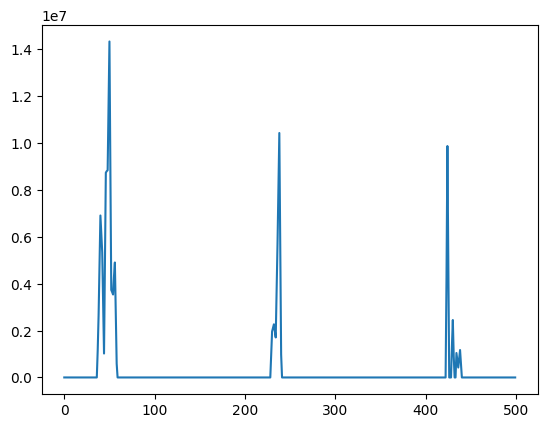

In [16]:
print(res_df.describe())
res_df['Bilanz [kW]'][0:500].plot()
#res_df.drop(columns='Agri_PV')[0:200].plot(alpha=0.5)

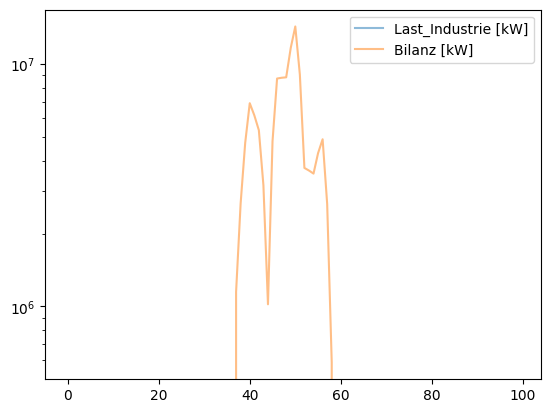

In [17]:
sol_index = len(pv_auswahl_1)
res_df.drop(res_df.columns[:-2],axis=1)[0:100].plot(alpha=0.5)
plt.yscale("log")
plt.show()

In [18]:
print(res_df.sum(axis=0)/4)



Windschutzwand           1.824053e+06
Schallschutzwand         1.926124e+06
Schallschutzwand_Dach    3.213258e+06
Böschung                 3.058882e+06
Agri_PV [kW]             2.833175e+10
Last_Industrie [kW]     -6.969525e+06
Bilanz [kW]              2.833480e+10
dtype: float64


In [19]:

# Mit Effizienz von 95% beim Laden und Entladen
storage = BatteryStorageEff(
    max_capacity_kwh=235000,
    initial_charge_kwh=250,
    charge_efficiency=0.9,
    discharge_efficiency=1
)

In [20]:
bat_result = storage.process_balance(res_df['Bilanz [kW]'], timestep_hours=0.25)
bat_result

,balance_kw,energy_balance_kwh,storage_charge_kwh,energy_to_grid_kwh,energy_from_grid_kwh
0,-1.5250,-0.381250,249.618750,0.0,0.000000
1,-528.2985,-132.074625,117.544125,0.0,0.000000
2,-495.4500,-123.862500,0.000000,0.0,6.318375
3,-473.9955,-118.498875,0.000000,0.0,118.498875
4,-475.9545,-118.988625,0.000000,0.0,118.988625
...,...,...,...,...,...
35035,-22.5000,-5.625000,234925.081249,0.0,0.000000
35036,-6.2000,-1.550000,234923.531249,0.0,0.000000
35037,-6.2000,-1.550000,234921.981249,0.0,0.000000
35038,-6.2000,-1.550000,234920.431249,0.0,0.000000


In [21]:
#lala = pd.read_csv("./outputs/res_df.csv", index_col=0)